# Порог по стоимости ошибок, кросс-валидация и проверка во времени

Продолжение `Credit_Card_Fraud_Detection.ipynb`. Те же данные, признаки и модель XGBoost. Здесь закрываю три ограничения из README:

1. Метрики были посчитаны на одном разбиении, без разброса.
2. Порог 0,5 не подбирался под стоимость ошибок.
3. Разбиение было случайным, а в антифроде модель всегда работает на транзакциях, которые случились **после** обучения.

In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, confusion_matrix
from xgboost import XGBClassifier

import os
if os.path.exists('creditcard.csv'):
    data = pd.read_csv('creditcard.csv')
else:
    with zipfile.ZipFile('creditcard.csv.zip') as z:
        data = pd.read_csv(z.open('creditcard.csv'))

data['Hour'] = (data['Time'] % 86400) // 3600
data['Amount_log'] = np.log1p(data['Amount'])
data['V17_V14'] = data['V17'] * data['V14']
data['V12_V17'] = data['V12'] * data['V17']
data = data.drop_duplicates().reset_index(drop=True)

def make_model():
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                         scale_pos_weight=500, eval_metric='aucpr',
                         random_state=42, n_jobs=-1)

def metrics(y, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return dict(precision=precision_score(y, pred), recall=recall_score(y, pred),
                f1=f1_score(y, pred), pr_auc=average_precision_score(y, proba),
                tp=tp, fp=fp, fn=fn)

print(data.shape, data['Class'].sum())

(283726, 35) 473


## 1. Кросс-валидация: насколько стабильны метрики

То же разбиение 80/20, что в основном ноутбуке (`random_state=42`). На train — стратифицированная 5-фолдовая кросс-валидация. Тест не трогаю до конца.

In [2]:
X = data.drop(columns='Class')
y = data['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
oof = np.zeros(len(y_train))
for k, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    m = make_model().fit(X_train.iloc[tr], y_train.iloc[tr])
    p = m.predict_proba(X_train.iloc[va])[:, 1]
    oof[va] = p
    rows.append({'fold': k, **metrics(y_train.iloc[va], p, 0.5)})

cv = pd.DataFrame(rows).set_index('fold')
display(cv.round(3))
summary = cv[['precision', 'recall', 'f1', 'pr_auc']].agg(['mean', 'std']).round(3)
summary

,precision,recall,f1,pr_auc,tp,fp,fn
fold,,,,,,,
1,0.952,0.800,0.870,0.839,60,3,15
2,0.887,0.840,0.863,0.868,63,8,12
3,0.879,0.763,0.817,0.792,58,8,18
4,0.833,0.855,0.844,0.855,65,13,11
5,0.857,0.868,0.863,0.864,66,11,10


,precision,recall,f1,pr_auc
mean,0.882,0.825,0.851,0.844
std,0.045,0.043,0.021,0.031


## 2. Порог по стоимости ошибок

Цена ошибок — допущение, его надо согласовать с бизнесом:

- **Пропущенный фрод (FN)** стоит суммы транзакции (`Amount`): деньги ушли мошеннику.
- **Ложное срабатывание (FP)** стоит фиксированно `C_FP`: звонок клиенту, ручная проверка, недовольство из-за блокировки. Беру 10 € и проверяю чувствительность.

Порог подбираю на out-of-fold предсказаниях train, на тесте применяю один раз.

In [3]:
amount_train = X_train['Amount'].values
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)

def total_cost(y, proba, amount, thr, c_fp):
    pred = proba >= thr
    fn_cost = amount[(y == 1) & ~pred].sum()
    fp_cost = c_fp * ((y == 0) & pred).sum()
    return fn_cost + fp_cost

y_tr = y_train.values
sens = []
for c_fp in [2, 5, 10, 25, 50]:
    costs = [total_cost(y_tr, oof, amount_train, t, c_fp) for t in thresholds]
    best = thresholds[int(np.argmin(costs))]
    sens.append({'C_FP': c_fp, 'лучший порог': best,
                 'стоимость при 0.5': round(total_cost(y_tr, oof, amount_train, 0.5, c_fp)),
                 'стоимость при лучшем': round(min(costs))})
sens = pd.DataFrame(sens)
sens

,C_FP,лучший порог,стоимость при 0.5,стоимость при лучшем
0,2,0.06,11028,10067
1,5,0.06,11157,10673
2,10,0.76,11372,11257
3,25,0.76,12017,11722
4,50,0.92,13092,12274


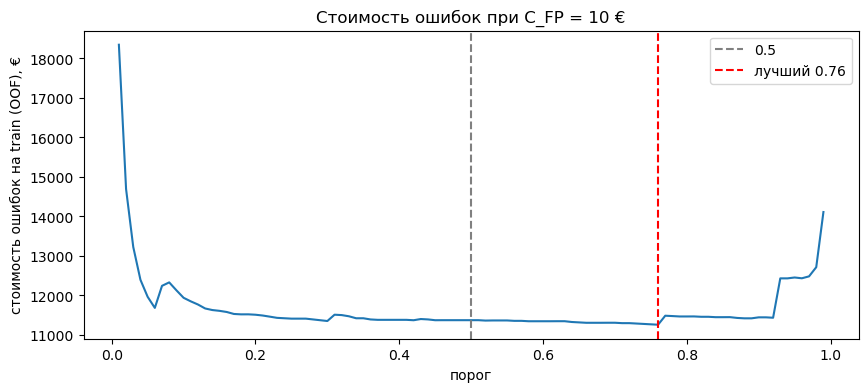

np.float64(0.76)

In [4]:
C_FP = 10
costs = [total_cost(y_tr, oof, amount_train, t, C_FP) for t in thresholds]
best_thr = thresholds[int(np.argmin(costs))]

plt.figure(figsize=(10, 4))
plt.plot(thresholds, costs)
plt.axvline(0.5, ls='--', c='grey', label='0.5')
plt.axvline(best_thr, ls='--', c='red', label=f'лучший {best_thr}')
plt.xlabel('порог'); plt.ylabel('стоимость ошибок на train (OOF), €')
plt.title(f'Стоимость ошибок при C_FP = {C_FP} €'); plt.legend(); plt.show()
best_thr

Проверка на тесте: модель обучена на всём train, порог взят с OOF.

In [5]:
model = make_model().fit(X_train, y_train)
proba_test = model.predict_proba(X_test)[:, 1]
amount_test = X_test['Amount'].values

res = []
for name, thr in [('порог 0.5', 0.5), (f'порог по стоимости ({best_thr})', best_thr)]:
    m = metrics(y_test, proba_test, thr)
    m['стоимость, €'] = round(total_cost(y_test.values, proba_test, amount_test, thr, C_FP))
    m['пропущено фрода, €'] = round(amount_test[(y_test.values == 1) & (proba_test < thr)].sum())
    res.append({'вариант': name, **m})
res = pd.DataFrame(res).set_index('вариант')
res.round(3)

,precision,recall,f1,pr_auc,tp,fp,fn,"стоимость, €","пропущено фрода, €"
вариант,,,,,,,,,
порог 0.5,0.884,0.800,0.840,0.812,76,10,19,3885,3785
порог по стоимости (0.76),0.948,0.768,0.849,0.812,73,4,22,3852,3812


Куда уходят деньги: пропущенный фрод при пороге 0,5.

In [6]:
miss = X_test.assign(score=proba_test, y=y_test.values).query('y == 1 and score < 0.5')
print('пропущено', len(miss), 'операций на', round(miss['Amount'].sum()), '€')
display(miss.sort_values('Amount', ascending=False)[['Amount', 'score', 'Hour']].head(10).round(3))
print('доля потерь в 3 самых крупных:', round(miss['Amount'].nlargest(3).sum() / miss['Amount'].sum(), 2))

пропущено 19 операций на 3785 €


,Amount,score,Hour
248322,1096.99,0.000,18.0
194676,723.21,0.026,12.0
100242,549.06,0.000,18.0
67805,519.90,0.000,14.0
145246,451.27,0.184,0.0
101128,320.00,0.001,18.0
52289,105.99,0.001,12.0
231118,8.00,0.002,16.0
228883,2.22,0.101,16.0
72475,1.79,0.000,15.0


доля потерь в 3 самых крупных: 0.63


## 3. Проверка во времени

Случайное разбиение подмешивает в train транзакции, которые случились позже тестовых. В проде так не бывает. Здесь train — первые 80% транзакций по `Time`, test — последние 20%. Признак `Time` убираю: на будущих данных его значения выходят за диапазон train.

In [7]:
d = data.sort_values('Time').reset_index(drop=True)
cut = int(len(d) * 0.8)
Xt = d.drop(columns=['Class', 'Time'])
yt = d['Class']
Xt_tr, Xt_te, yt_tr, yt_te = Xt.iloc[:cut], Xt.iloc[cut:], yt.iloc[:cut], yt.iloc[cut:]
print('train до', d['Time'].iloc[cut - 1], 'с; фрода в train', yt_tr.sum(), ', в test', yt_te.sum())

m_time = make_model().fit(Xt_tr, yt_tr)
p_time = m_time.predict_proba(Xt_te)[:, 1]

# для сравнения: случайное разбиение без признака Time
m_rand = make_model().fit(X_train.drop(columns='Time'), y_train)
p_rand = m_rand.predict_proba(X_test.drop(columns='Time'))[:, 1]

cmp = pd.DataFrame([
    {'разбиение': 'случайное, без Time', **metrics(y_test, p_rand, 0.5)},
    {'разбиение': 'по времени, без Time', **metrics(yt_te, p_time, 0.5)},
]).set_index('разбиение')
cmp.round(3)

train до 145233.0 с; фрода в train 399 , в test 74


,precision,recall,f1,pr_auc,tp,fp,fn
разбиение,,,,,,,
"случайное, без Time",0.890,0.768,0.825,0.805,73,9,22
"по времени, без Time",0.824,0.757,0.789,0.793,56,12,18


## Выводы

- **Метрики стабильны.** На 5 фолдах train: precision 0,88 ± 0,05, recall 0,83 ± 0,04, PR-AUC 0,84 ± 0,03. Результат на тесте (0,88 / 0,80 / 0,81) лежит внутри этого разброса, то есть одно разбиение не было удачным случаем.
- **Порог почти не влияет на деньги.** Кривая стоимости плоская: при C_FP = 10 € лучший порог 0,76 срезает ложные срабатывания с 10 до 4, но экономит на тесте около 1%. Лучший порог прыгает между 0,06 и 0,76 при небольшой смене C_FP — ещё один признак плоской кривой. Почти вся стоимость — пропущенный фрод: 19 операций на 3 785 €, из них три самые крупные дают 63% потерь, и скор у них около нуля. Рычаг тут не порог, а признаки, которые поймали бы эти операции.
- **Во времени модель проседает, но умеренно.** На последних 20% транзакций precision падает с 0,89 до 0,82, recall почти не меняется (0,77 → 0,76), PR-AUC 0,81 → 0,79. В тесте всего 74 случая фрода, так что разница в пределах шума, но направление ожидаемое: в проде метрики будут ниже, чем на случайном разбиении.
- **Признак `Time` лучше не брать.** Со `Time` на случайном разбиении recall 0,80, без него 0,77. Модель частично запоминает момент двухдневной выгрузки, на новых данных это не сработает.

Ограничения те же: данные за два дня, признаки анонимизированы, стоимость FP — допущение.